# 03 NLP: van omschrijving naar getallen

**Workshop:** LU2 `05_NLP` (opschonen, tokenisatie, stopwoorden, lemmatisatie en stemming, Bag of Words).

De workshop gebruikt Engelse tekst. Onze catalogus is **Nederlands**, dus we gebruiken een Nederlandse stopwoordenlijst en de
Nederlandse Snowball stemmer. Daarna gaan we van Bag of Words naar **TF-IDF**, dat zeldzame en dus onderscheidende woorden zwaarder laat wegen.

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from leescoach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from leescoach.data_cleaning import load_processed
from leescoach.text import DUTCH_STOPWORDS, normalize, preprocess, remove_stopwords, stem, tokenize

materials, students, interactions = load_processed()
example = materials.loc[0, "tekst"]
example

'Het dagboek van Anne Frank. Dagboek van een Joods meisje dat tijdens de Tweede Wereldoorlog onderduikt in Amsterdam. Haar persoonlijke observaties geven een indringend beeld van angst, hoop, groei en het dagelijks leven onder vervolging.. woii onderduik'

## 1. Normaliseren: kleine letters, cijfers en leestekens weg

In [3]:
cleaned = normalize(example)
cleaned

'het dagboek van anne frank dagboek van een joods meisje dat tijdens de tweede wereldoorlog onderduikt in amsterdam haar persoonlijke observaties geven een indringend beeld van angst hoop groei en het dagelijks leven onder vervolging woii onderduik'

## 2. Tokenisatie

In [4]:
tokens = tokenize(example)
print(len(tokens), "tokens")
tokens

37 tokens


['het',
 'dagboek',
 'van',
 'anne',
 'frank',
 'dagboek',
 'van',
 'een',
 'joods',
 'meisje',
 'dat',
 'tijdens',
 'de',
 'tweede',
 'wereldoorlog',
 'onderduikt',
 'in',
 'amsterdam',
 'haar',
 'persoonlijke',
 'observaties',
 'geven',
 'een',
 'indringend',
 'beeld',
 'van',
 'angst',
 'hoop',
 'groei',
 'en',
 'het',
 'dagelijks',
 'leven',
 'onder',
 'vervolging',
 'woii',
 'onderduik']

## 3. Stopwoorden verwijderen
Naast gewone stopwoorden (de, het, een) halen we ook woorden weg die in bijna elke omschrijving staan, zoals *verhaal* en *boek*. Die zeggen niets over het onderwerp.

In [5]:
without_stopwords = remove_stopwords(tokens)
print(f"{len(DUTCH_STOPWORDS)} stopwoorden in de lijst")
without_stopwords

135 stopwoorden in de lijst


['dagboek',
 'anne',
 'frank',
 'dagboek',
 'joods',
 'meisje',
 'tweede',
 'wereldoorlog',
 'onderduikt',
 'amsterdam',
 'persoonlijke',
 'observaties',
 'geven',
 'indringend',
 'beeld',
 'angst',
 'hoop',
 'groei',
 'dagelijks',
 'leven',
 'vervolging',
 'woii',
 'onderduik']

## 4. Stemming
NLTK heeft geen Nederlandse WordNet lemmatizer, daarom gebruiken we stemming. Een stam hoeft geen echt woord te zijn: dat is prima, zolang *vriendschap* en *vriendschappen* dezelfde stam krijgen.

In [6]:
from nltk.stem.snowball import SnowballStemmer

stemmer = SnowballStemmer("dutch")
for word in ["vriendschap", "vriendschappen", "oorlogen", "spannende", "spanning", "jongeren", "opgroeien"]:
    print(f"{word:16s} -> {stemmer.stem(word)}")
print()
print(stem(without_stopwords))

vriendschap      -> vriendschap
vriendschappen   -> vriendschapp
oorlogen         -> oorlog
spannende        -> spannend
spanning         -> spanning
jongeren         -> jonger
opgroeien        -> opgroei

['dagboek', 'ann', 'frank', 'dagboek', 'jod', 'meisj', 'twed', 'wereldoorlog', 'onderduikt', 'amsterdam', 'person', 'observaties', 'gev', 'indring', 'beeld', 'angst', 'hop', 'groei', 'dagelijk', 'lev', 'vervolg', 'woii', 'onderduik']


## 5. Bag of Words

Bag of Words: (275, 1054) (1.0% gevuld)


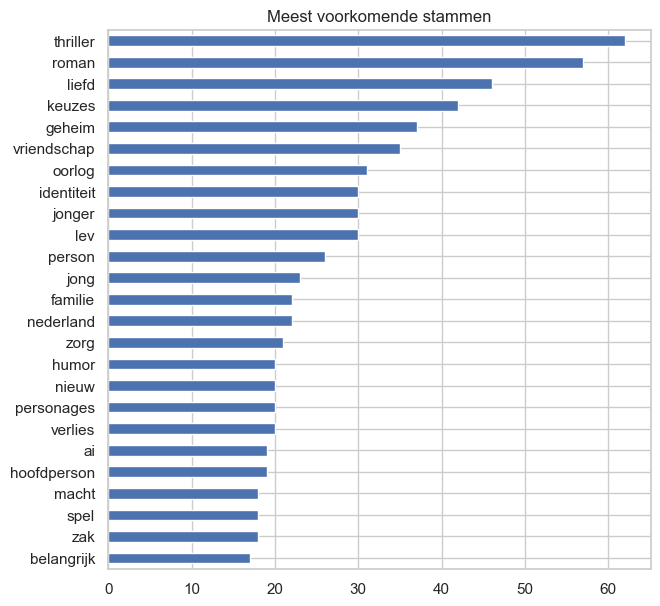

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

documents = materials["tekst"].fillna("").map(preprocess)
bow = CountVectorizer()
bow_matrix = bow.fit_transform(documents)
print("Bag of Words:", bow_matrix.shape, f"({bow_matrix.nnz / np.prod(bow_matrix.shape):.1%} gevuld)")
word_counts = pd.Series(np.asarray(bow_matrix.sum(axis=0)).ravel(), index=bow.get_feature_names_out()).nlargest(25)
word_counts.plot.barh(figsize=(7, 7), title="Meest voorkomende stammen").invert_yaxis()
plt.show()

## 6. TF-IDF
TF-IDF = hoe vaak een woord in dit document staat, maal hoe zeldzaam het is in alle documenten. Hieronder de woorden die voor een paar materialen het meest kenmerkend zijn.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
tfidf_matrix = tfidf.fit_transform(documents)
terms = tfidf.get_feature_names_out()
for position in [0, 1, 150, 170]:
    row = tfidf_matrix[position].toarray().ravel()
    top = terms[row.argsort()[::-1][:6]]
    print(f"{materials.loc[position, 'titel'][:45]:45s} {', '.join(top)}")

Het dagboek van Anne Frank                    dagboek, onderduikt, jod meisj, dagboek ann, vervolg woii, observaties gev
Blauw Water                                   stalking, spanning, water spannend, water, spanning oploopt, oploopt zet
CPB: het gaat goed met de Nederlandse economi economie, staatsschuld oplop, staatsschuld, oplop, goed nederland, economie staatsschuld
We zijn evenwijdig                            we evenwijd, tal ontmoet, evenwijd communicatie, evenwijd, communicatie tal, communicatie


## 7. Interesses van studenten matchen
De student zegt *kunstmatige intelligentie*, de catalogus zegt *AI*. Zonder hulp vindt TF-IDF die match niet. Daarom breiden we interesses uit met synoniemen.

In [9]:
from leescoach.text import expand_interests
from sklearn.metrics.pairwise import cosine_similarity

interest = ["kunstmatige intelligentie"]
for label, text in [("zonder synoniemen", " ".join(interest)), ("met synoniemen", expand_interests(interest))]:
    vector = tfidf.transform([preprocess(text)])
    similarity = cosine_similarity(vector, tfidf_matrix).ravel()
    print(f"{label}: {int((similarity > 0).sum())} materialen met overlap, beste: {materials.loc[similarity.argmax(), 'titel']}")

zonder synoniemen: 0 materialen met overlap, beste: Het dagboek van Anne Frank
met synoniemen: 19 materialen met overlap, beste: AI-verordening


## Conclusie

* De Nederlandse pipeline (normaliseren, tokenizen, stopwoorden, stemmen) staat in `src/leescoach/text.py` en wordt door het
  model en de API gebruikt.
* TF-IDF met unigrammen en bigrammen is de tekstrepresentatie voor het content based deel (notebook 04).
* **Mogelijke verbetering:** meertalige *sentence embeddings* (bijvoorbeeld een sentence transformers model) begrijpen
  betekenis zonder synoniemenlijst. Dat kost wel meer rekenkracht en een extra afhankelijkheid, en voor 275 korte
  omschrijvingen werkt TF-IDF met synoniemen al goed.